# Análise exploratória dos dados

Este notebook descreve os dados usados pelo recomendador e justifica as decisões de limpeza e pré-processamento. Fonte: [Game Recommendations on Steam](https://www.kaggle.com/datasets/antonkozyriev/game-recommendations-on-steam) (Anton Kozyriev, Kaggle).

São três arquivos:

- `games.csv`: um jogo por linha, com título, data de lançamento, preço e número de avaliações;
- `games_metadata.json`: descrição e tags de cada jogo;
- `recommendations.csv`: 41 milhões de avaliações "recomendo / não recomendo" de usuários.

O notebook usa as mesmas funções do sistema (`backend/app/recommender/`), então o que aparece aqui é exatamente o que o modelo recebe. As figuras são salvas em `results/eda/` para o relatório e os slides.

**Como executar:** baixe os dados (seção "Baixar o dataset" do README), rode `python scripts/prepare_data.py` e execute todas as células. Leva cerca de 1 minuto; a maior parte é a leitura de `recommendations.csv` em blocos. O `scripts/reproduzir.py` já faz tudo isso.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from backend.app.evaluation.split import itens_relevantes, split_temporal
from backend.app.recommender.catalogo import EXTRAS, caminhos_catalogo, carregar_catalogo
from backend.app.recommender.modelo import LIMITE_Z, _numericos_brutos, _padronizar, _tokens

FIGURAS = RAIZ / "results" / "eda"
FIGURAS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.2f}".format)
COR, COR2 = "#2f6f8f", "#d08c3a"


def salvar(fig, nome):
    """Salva a figura em results/eda/ para o relatório e os slides."""
    fig.tight_layout()
    fig.savefig(FIGURAS / f"{nome}.png", dpi=150, bbox_inches="tight")

## 1. Catálogo de jogos

Os dois arquivos do catálogo têm um registro por jogo e são unidos pelo `app_id`. Para a filtragem baseada em conteúdo, o que importa é a **descrição** e as **tags** (texto). Preço e data de lançamento são os atributos numéricos. Ficaram de fora de propósito `rating`, `positive_ratio` e `user_reviews`: eles resumem opiniões de outros usuários, e a FBC deve usar só características do próprio item. `user_reviews` é usado apenas para escolher o recorte do catálogo, nunca no cálculo da similaridade.

In [2]:
jogos_csv, metadados_json = caminhos_catalogo()
jogos = pd.read_csv(jogos_csv)
metadados = pd.read_json(metadados_json, lines=True)
bruto = jogos.merge(metadados, on="app_id", how="left")
print(f"games.csv: {len(jogos):,} jogos | games_metadata.json: {len(metadados):,} registros")
print("Colunas:", ", ".join(bruto.columns))
bruto[["app_id", "title", "date_release", "price_final", "user_reviews", "tags", "description"]].head(3)

games.csv: 50,872 jogos | games_metadata.json: 50,872 registros
Colunas: app_id, title, date_release, win, mac, linux, rating, positive_ratio, user_reviews, price_final, price_original, discount, steam_deck, description, tags


,app_id,title,date_release,price_final,user_reviews,tags,description
0,13500,Prince of Persia: Warrior Within™,2008-11-21,9.99,2199,"[Action, Adventure, Parkour, Third Person, Gre...",Enter the dark underworld of Prince of Persia ...
1,22364,BRINK: Agents of Change,2011-08-03,2.99,21,[Action],
2,113020,Monaco: What's Yours Is Mine,2013-04-24,14.99,3722,"[Co-op, Stealth, Indie, Heist, Local Co-Op, St...",Monaco: What's Yours Is Mine is a single playe...


### 1.1 Valores ausentes

In [3]:
descricao_vazia = bruto["description"].fillna("").str.strip().eq("")
sem_tags = bruto["tags"].apply(lambda t: not isinstance(t, list) or len(t) == 0)
ausentes = pd.Series({
    "descrição vazia ou ausente": descricao_vazia.sum(),
    "sem tags": sem_tags.sum(),
    "sem descrição e sem tags": (descricao_vazia & sem_tags).sum(),
    "date_release ausente": bruto["date_release"].isna().sum(),
    "price_final ausente": bruto["price_final"].isna().sum(),
    "price_final = 0 (gratuito)": (bruto["price_final"] == 0).sum(),
}, name="jogos").to_frame()
ausentes["% do catálogo"] = 100 * ausentes["jogos"] / len(bruto)
ausentes

,jogos,% do catálogo
descrição vazia ou ausente,10373,20.39
sem tags,1244,2.45
sem descrição e sem tags,1229,2.42
date_release ausente,0,0.00
price_final ausente,0,0.00
price_final = 0 (gratuito),9105,17.90


**Leitura.** O problema de qualidade está no texto, não nos números: **um em cada cinco jogos não tem descrição**. Preço e data estão sempre preenchidos. O código imputa a mediana caso falte algum valor, mas esse caminho não é usado com este dataset. Jogo gratuito (preço 0) é um valor legítimo, não um ausente.

### 1.2 Quais jogos não têm descrição?

Se os jogos sem descrição fossem só títulos obscuros, descartá-los não faria diferença. A célula abaixo mostra que não é o caso.

In [4]:
total_avaliacoes = bruto["user_reviews"].sum()
grupos = pd.DataFrame({
    "jogos": [(descricao_vazia & sem_tags).sum(), (descricao_vazia & ~sem_tags).sum(), (~descricao_vazia).sum()],
    "% das avaliações": [100 * bruto.loc[m, "user_reviews"].sum() / total_avaliacoes
                         for m in (descricao_vazia & sem_tags, descricao_vazia & ~sem_tags, ~descricao_vazia)],
}, index=["sem descrição e sem tags", "sem descrição, com tags", "com descrição"])
display(grupos)

print("Mais avaliados SEM descrição e SEM tags:")
display(bruto[descricao_vazia & sem_tags].nlargest(8, "user_reviews")[["title", "user_reviews"]])
print("Mais avaliados sem descrição, mas COM tags:")
display(bruto[descricao_vazia & ~sem_tags].nlargest(8, "user_reviews")[["title", "user_reviews"]])

,jogos,% das avaliações
sem descrição e sem tags,1229,61.76
"sem descrição, com tags",9144,1.20
com descrição,40499,37.05


Mais avaliados SEM descrição e SEM tags:


,title,user_reviews
14398,Counter-Strike: Global Offensive,7494460
47770,PUBG: BATTLEGROUNDS,2217226
13176,Dota 2,2045628
12717,Grand Theft Auto V,1484122
14535,Tom Clancy's Rainbow Six® Siege,993312
47380,Team Fortress 2,985819
13035,Terraria,943413
15363,Garry's Mod,853733


Mais avaliados sem descrição, mas COM tags:


,title,user_reviews
39250,Ragnarok - ARK Expansion Map,10768
8936,Unturned - Permanent Gold Upgrade,9365
30459,Grand Theft Auto V - Criminal Enterprise Start...,8519
920,The Witcher 3: Wild Hunt - Blood and Wine,7923
48662,Poppy Playtime - Chapter 2,7255
48598,Elite Dangerous: Odyssey,7011
41269,The Center - ARK Expansion Map,6534
44028,Total War: WARHAMMER II - Mortal Empires,5705


**Leitura (principal limitação dos dados).** O metadado falta justamente nos maiores jogos. Cerca de 1.200 jogos não têm **nem descrição nem tags**, e eles concentram **~62% de todas as avaliações da base**: Counter-Strike: GO, PUBG, Dota 2, GTA V, Terraria, Rust... Sem nenhum texto, eles **não podem ser recomendados nem entrar no perfil** de quem os jogou. É o exemplo concreto da "dependência da qualidade dos metadados" da FBC. Já os ~9 mil jogos sem descrição mas com tags são quase todos DLCs e expansões ("ARK Expansion Map", "Blood and Wine"...) e somam só ~1% das avaliações. Portanto, aceitar jogos só com tags quase não ajudaria. O próximo passo seria completar os metadados dos grandes jogos com uma fonte externa, como a API da loja Steam.

## 2. Do arquivo bruto ao catálogo usado

O catálogo passa por três filtros (`backend/app/recommender/catalogo.py`):

1. exige descrição não vazia, porque o TF-IDF precisa de texto;
2. remove itens que não são jogos, identificados pelo título (trilha sonora, DLC, passe de temporada, prólogo...);
3. mantém os 8.000 mais avaliados, para a interface carregar rápido e o catálogo ter jogos que os usuários conhecem.

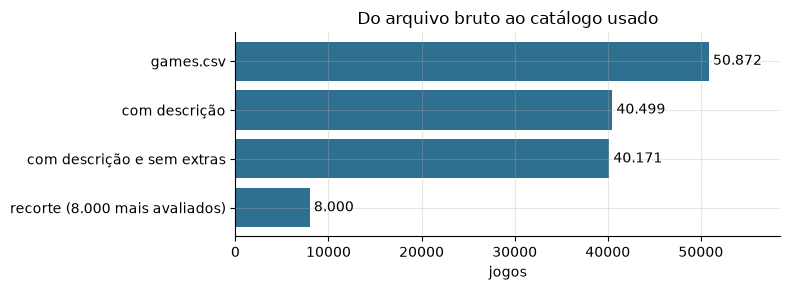

Títulos removidos como extras (amostra com semente 42):
      Aztlan Uncovered: Prologue
          Doll Explorer Prologue
                 PROZE: Prologue
                   Final Upgrade
    Die in the Dungeon: PROLOGUE
   Lost Circus VR - The Prologue
          Lhama Clicker Prologue
     Monuments Flipper: Prologue
              Backbone: Prologue
Steam Summer Monsters Soundtrack
              Koncolos: Prologue
     Force of Nature 2: Prologue


In [5]:
extra = bruto["title"].map(lambda titulo: bool(EXTRAS.search(titulo)))
demo = carregar_catalogo(8000)
etapas = pd.Series({
    "games.csv": len(bruto),
    "com descrição": (~descricao_vazia).sum(),
    "com descrição e sem extras": (~descricao_vazia & ~extra).sum(),
    "recorte (8.000 mais avaliados)": len(demo),
}, name="jogos")

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(etapas.index[::-1], etapas.values[::-1], color=COR)
for i, v in enumerate(etapas.values[::-1]):
    ax.text(v, i, f" {v:,}".replace(",", "."), va="center")
ax.set_xlabel("jogos")
ax.set_title("Do arquivo bruto ao catálogo usado")
ax.set_xlim(0, etapas.max() * 1.15)
salvar(fig, "01_funil_catalogo")
plt.show()

print("Títulos removidos como extras (amostra com semente 42):")
print(bruto.loc[extra & ~descricao_vazia, "title"].sample(12, random_state=42).to_string(index=False))

**Leitura.** O filtro de extras é heurístico. Na amostra acima, quase todos os removidos são **prólogos** (demos gratuitas, que duplicam o jogo principal) e trilhas sonoras, o que está correto. Pode haver falsos positivos, como "Final Upgrade", que parece ser um jogo de verdade. O efeito é pequeno: na amostra de usuários, só 17 interações foram perdidas por esse filtro (seção 7).

## 3. Popularidade dos jogos

Mediana de avaliações por jogo: 49 | média: 1,824
Os 8.000 jogos do recorte concentram 34.5% de todas as avaliações (user_reviews)
Top 1% dos jogos (508) = 69.6% das avaliações
Top 10% dos jogos (5,087) = 94.1% das avaliações


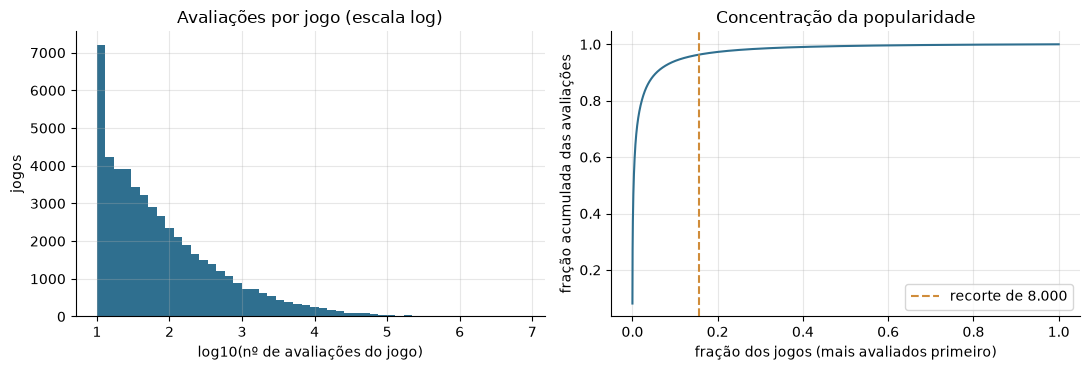

In [6]:
reviews = bruto["user_reviews"].sort_values(ascending=False).to_numpy()
acumulado = reviews.cumsum() / reviews.sum()
participacao_recorte = bruto.loc[bruto["app_id"].isin(demo), "user_reviews"].sum() / reviews.sum()
print(f"Mediana de avaliações por jogo: {np.median(reviews):,.0f} | média: {reviews.mean():,.0f}")
print(f"Os 8.000 jogos do recorte concentram {participacao_recorte:.1%} de todas as avaliações (user_reviews)")
for topo in (0.01, 0.10):
    n = int(len(reviews) * topo)
    print(f"Top {topo:.0%} dos jogos ({n:,}) = {acumulado[n - 1]:.1%} das avaliações")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
a.hist(np.log10(bruto["user_reviews"].clip(lower=1)), bins=50, color=COR)
a.set_xlabel("log10(nº de avaliações do jogo)")
a.set_ylabel("jogos")
a.set_title("Avaliações por jogo (escala log)")
b.plot(np.arange(1, len(acumulado) + 1) / len(acumulado), acumulado, color=COR)
b.axvline(8000 / len(acumulado), color=COR2, ls="--", label="recorte de 8.000")
b.set_xlabel("fração dos jogos (mais avaliados primeiro)")
b.set_ylabel("fração acumulada das avaliações")
b.set_title("Concentração da popularidade")
b.legend()
salvar(fig, "02_popularidade_jogos")
plt.show()

**Leitura.** A popularidade é extremamente concentrada (cauda longa): a mediana é 49 avaliações por jogo, mas 1% dos jogos recebe 70% delas. Isso justifica o baseline de **mais populares**: recomendar sempre os mesmos sucessos já acerta bastante. Também mostra o risco desse baseline, que tem cobertura quase nula. O recorte de 8.000 jogos cobre só 34,5% das avaliações, e não ~95%, porque os maiores sucessos ficaram de fora por não terem metadados (seção 1.2).

## 4. Texto: descrições e tags

            count  mean   std  min   10%   50%   90%   max
palavras 8,000.00 35.15 12.91 1.00 16.00 37.00 50.00 79.00
n_tags   8,000.00 16.61  4.79 1.00  9.00 20.00 20.00 20.00

439 tags distintas; 0 jogos do recorte sem tags


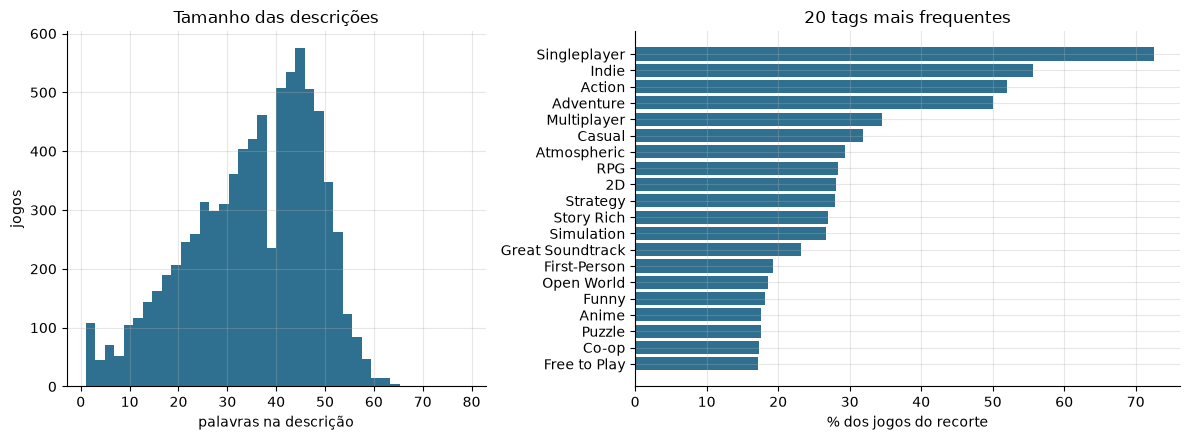

In [7]:
recorte = pd.DataFrame(demo.values())
recorte["palavras"] = recorte["description"].str.split().str.len()
recorte["n_tags"] = recorte["tags"].str.len()
print(recorte[["palavras", "n_tags"]].describe(percentiles=[0.1, 0.5, 0.9]).T)

contagem_tags = pd.Series([t for tags in recorte["tags"] for t in tags]).value_counts()
print(f"\n{len(contagem_tags):,} tags distintas; {(recorte['n_tags'] == 0).sum()} jogos do recorte sem tags")

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
a.hist(recorte["palavras"], bins=40, color=COR)
a.set_xlabel("palavras na descrição")
a.set_ylabel("jogos")
a.set_title("Tamanho das descrições")
top = contagem_tags.head(20)[::-1]
b.barh(top.index, 100 * top.values / len(recorte), color=COR)
b.set_xlabel("% dos jogos do recorte")
b.set_title("20 tags mais frequentes")
salvar(fig, "03_texto_e_tags")
plt.show()

**Leitura.** As descrições são **curtas**: mediana de 37 palavras, ou seja, um parágrafo de chamada, não o texto completo da loja. Já as tags são ricas: 17 por jogo em média, com limite de 20, e 439 tags distintas, sem nenhum jogo do recorte sem tags. Por isso o modelo dá **peso 4 a cada tag inteira**, contra 1 para cada palavra da descrição: com tão pouco texto, as tags descrevem melhor o estilo do jogo. As tags mais comuns (Singleplayer, Action, Adventure...) aparecem em mais da metade dos jogos e quase não discriminam. O IDF do TF-IDF reduz o peso delas automaticamente.

### 4.1 Efeito do pré-processamento

O pré-processamento converte para minúsculas, remove acentos e pontuação, tira stopwords em português e inglês (incluindo palavras do domínio como *game*, *play* e *player*, que estão em toda descrição) e aplica um stemming leve de sufixos.

In [8]:
exemplo = demo[max(demo, key=lambda i: demo[i]["user_reviews"])]
print("Título:", exemplo["title"])
print("\nOriginal:\n", exemplo["description"])
print("\nApós o pré-processamento (minúsculas, sem acento/pontuação, sem stopwords, stemming):\n",
      " ".join(_tokens(exemplo["description"])))

import re
bruto_tokens = [w for d in recorte["description"] for w in re.findall(r"[a-z0-9]+", d.lower())]
tratados = [t for d in recorte["description"] for t in _tokens(d)]
vocabulario = pd.DataFrame({
    "tokens": [len(bruto_tokens), len(tratados)],
    "vocabulário distinto": [len(set(bruto_tokens)), len(set(tratados))],
}, index=["texto bruto", "após pré-processamento"])
vocabulario["redução do vocabulário"] = 1 - vocabulario["vocabulário distinto"] / vocabulario["vocabulário distinto"].iloc[0]
vocabulario

Título: Unturned

Original:
 You're a survivor in the zombie infested ruins of society, and must work with your friends and forge alliances to remain among the living.

Após o pré-processamento (minúsculas, sem acento/pontuação, sem stopwords, stemming):
 survivor zombie infest ruin society must work friend forge allianc remain among liv


,tokens,vocabulário distinto,redução do vocabulário
texto bruto,289029,19468,0.00
após pré-processamento,170731,15598,0.20


**Leitura.** O pré-processamento elimina cerca de 40% dos tokens (stopwords) e reduz o vocabulário em 20% (o stemming junta *friend/friends*, *infested/infest*). O stemming é simples e às vezes corta demais (*living* → *liv*, *alliances* → *allianc*), mas como a mesma regra vale para todos os jogos, termos iguais continuam iguais, que é o que o cosseno precisa.

## 5. Atributos numéricos: preço e ano

Esses atributos são usados apenas na variante "Conteúdo + preço/ano" (ver `docs/avaliacao.md`).

Preço: mediana US$ 9.99, média US$ 12.35, máximo US$ 99.99, 20.3% gratuitos
Assimetria (skewness) do preço: bruto = 1.53 | log(1 + preço) = -0.55
Ano de lançamento: 1997 a 2023, mediana 2018; 0 ausentes (recebem a mediana)
Valores no limite de ±3 após o z-score: preço 0.0%, ano 0.6%


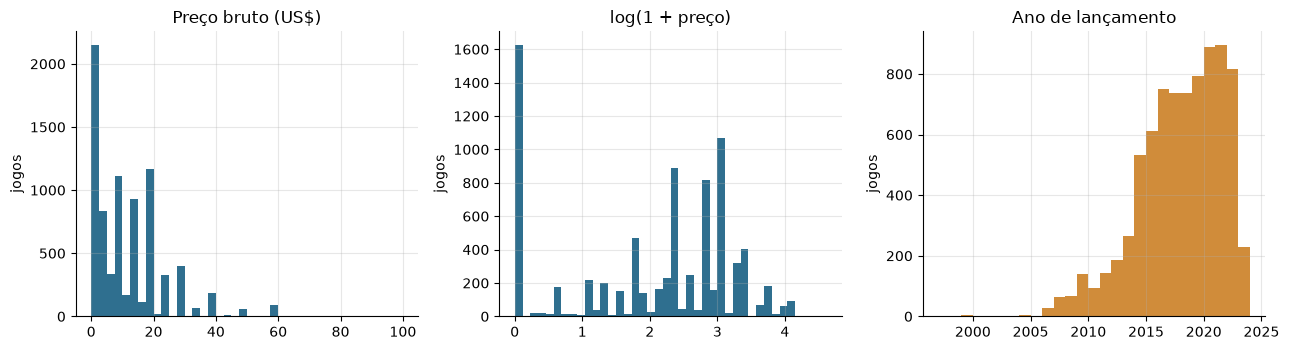

In [9]:
numericos = pd.DataFrame([_numericos_brutos(j) for j in demo.values()])
preco = recorte["price_final"]
ano = numericos["num:ano"]
print(f"Preço: mediana US$ {preco.median():.2f}, média US$ {preco.mean():.2f}, máximo US$ {preco.max():.2f}, "
      f"{(preco == 0).mean():.1%} gratuitos")
print(f"Assimetria (skewness) do preço: bruto = {preco.skew():.2f} | log(1 + preço) = {np.log1p(preco).skew():.2f}")
print(f"Ano de lançamento: {ano.min():.0f} a {ano.max():.0f}, mediana {ano.median():.0f}; "
      f"{ano.isna().sum()} ausentes (recebem a mediana)")

z = pd.DataFrame(_padronizar(demo)).T.reindex(columns=["num:preco", "num:ano"]).fillna(0.0)
limitados = (z.abs() >= LIMITE_Z).mean()
print(f"Valores no limite de ±{LIMITE_Z:g} após o z-score: preço {limitados['num:preco']:.1%}, "
      f"ano {limitados['num:ano']:.1%}")

fig, eixos = plt.subplots(1, 3, figsize=(13, 3.6))
eixos[0].hist(preco, bins=40, color=COR)
eixos[0].set_title("Preço bruto (US$)")
eixos[1].hist(np.log1p(preco), bins=40, color=COR)
eixos[1].set_title("log(1 + preço)")
eixos[2].hist(ano.dropna(), bins=range(int(ano.min()), int(ano.max()) + 2), color=COR2)
eixos[2].set_title("Ano de lançamento")
for eixo in eixos:
    eixo.set_ylabel("jogos")
salvar(fig, "04_atributos_numericos")
plt.show()

**Leitura.** O preço é **assimétrico à direita**: muitos jogos gratuitos ou baratos e uma cauda até US$ 100 (skewness 1,53). Aplicar `log(1 + preço)` deixa a distribuição bem mais simétrica (−0,55), e por isso o log vem antes do z-score. O z-score coloca preço e ano na mesma escala e centra em zero; o limite de ±3 só afeta 0,6% dos anos, os poucos jogos muito antigos. O catálogo se concentra em jogos recentes (mediana 2018).

## 6. Interações dos usuários (`recommendations.csv` completo)

O arquivo tem 2 GB, então é lido em blocos, só com as colunas necessárias.

In [10]:
caminho_rec = next(p for p in (RAIZ / "data" / "raw" / "recommendations.csv",) if p.exists())
por_usuario = np.zeros(1, dtype=np.int64)
por_jogo = np.zeros(1, dtype=np.int64)
linhas = positivas = 0
datas_min, datas_max = [], []
for pedaco in pd.read_csv(caminho_rec, usecols=["user_id", "app_id", "is_recommended", "date"],
                          chunksize=4_000_000):
    u = np.bincount(pedaco["user_id"].to_numpy())
    j = np.bincount(pedaco["app_id"].to_numpy())
    por_usuario = np.pad(por_usuario, (0, max(0, len(u) - len(por_usuario))))
    por_jogo = np.pad(por_jogo, (0, max(0, len(j) - len(por_jogo))))
    por_usuario[:len(u)] += u
    por_jogo[:len(j)] += j
    linhas += len(pedaco)
    positivas += int(pedaco["is_recommended"].sum())
    datas_min.append(pedaco["date"].min())
    datas_max.append(pedaco["date"].max())

por_usuario = por_usuario[por_usuario > 0]
por_jogo = np.sort(por_jogo[por_jogo > 0])[::-1]
geral = pd.Series({
    "interações (avaliações)": f"{linhas:,}",
    "usuários": f"{len(por_usuario):,}",
    "jogos avaliados": f"{len(por_jogo):,}",
    "período": f"{min(datas_min)} a {max(datas_max)}",
    "avaliações positivas": f"{positivas / linhas:.1%}",
    "mediana de avaliações por usuário": f"{np.median(por_usuario):.0f}",
    "usuários com 1 avaliação": f"{(por_usuario == 1).mean():.1%}",
    "usuários com ≥ 5 avaliações": f"{(por_usuario >= 5).mean():.1%}",
    "densidade da matriz usuário × jogo": f"{linhas / (len(por_usuario) * len(por_jogo)):.6%}",
}, name="recommendations.csv").to_frame()
geral

,recommendations.csv
interações (avaliações),"41,154,794"
usuários,"13,781,059"
jogos avaliados,"37,610"
período,2010-10-15 a 2022-12-31
avaliações positivas,85.8%
mediana de avaliações por usuário,1
usuários com 1 avaliação,55.0%
usuários com ≥ 5 avaliações,13.9%
densidade da matriz usuário × jogo,0.007940%


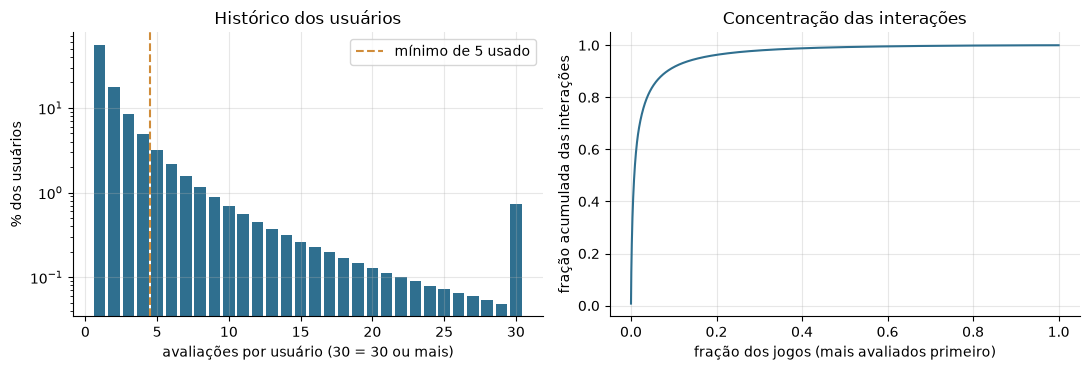

Top 1% dos jogos recebe 55.6% das interações; top 10% recebe 91.6%


In [11]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
valores, contagens = np.unique(np.minimum(por_usuario, 30), return_counts=True)
a.bar(valores, 100 * contagens / contagens.sum(), color=COR)
a.axvline(4.5, color=COR2, ls="--", label="mínimo de 5 usado")
a.set_xlabel("avaliações por usuário (30 = 30 ou mais)")
a.set_ylabel("% dos usuários")
a.set_yscale("log")
a.set_title("Histórico dos usuários")
a.legend()
acum = por_jogo.cumsum() / por_jogo.sum()
b.plot(np.arange(1, len(acum) + 1) / len(acum), acum, color=COR)
b.set_xlabel("fração dos jogos (mais avaliados primeiro)")
b.set_ylabel("fração acumulada das interações")
b.set_title("Concentração das interações")
salvar(fig, "05_interacoes")
plt.show()
print(f"Top 1% dos jogos recebe {acum[int(len(acum) * 0.01) - 1]:.1%} das interações; "
      f"top 10% recebe {acum[int(len(acum) * 0.10) - 1]:.1%}")

**Leitura.**

- **Positivas dominam (86%).** Na Steam, quem avalia em geral recomenda. Por isso "relevante" é definido como `is_recommended = True`: é o único sinal explícito de que o usuário gostou. As avaliações negativas são raras, então o peso negativo no perfil quase não age.
- **A maioria dos usuários quase não tem histórico.** A mediana é **1 avaliação por usuário**, e só 14% têm 5 ou mais. Com 1 ou 2 jogos não dá para separar treino e teste nem montar um perfil, por isso a amostra exige **pelo menos 5 jogos por usuário**. A avaliação, portanto, representa usuários ativos, não o usuário típico.
- **A matriz é extremamente esparsa** (0,008% preenchida). É o cenário em que a filtragem colaborativa sofre e a FBC, que depende só dos itens, faz sentido.
- As interações também se concentram: 1% dos jogos recebe 56% delas.

## 7. A amostra usada na avaliação

`scripts/prepare_data.py` sorteia 500 usuários com ≥ 5 jogos (semente 42). A tabela mostra o que sobra em cada etapa até o split temporal.

In [12]:
amostra = pd.read_csv(RAIZ / "data" / "processed" / "interacoes.csv", parse_dates=["date"])
catalogo_aval = carregar_catalogo(8000, amostra["app_id"].unique())
filtrada = amostra[amostra["app_id"].isin(catalogo_aval)].reset_index(drop=True)
treino, teste = split_temporal(filtrada)
relevantes = itens_relevantes(teste)

def resumo(df):
    n = df.groupby("user_id")["app_id"].count()
    return {"interações": len(df), "usuários": df["user_id"].nunique(), "jogos": df["app_id"].nunique(),
            "% positivas": f"{df['is_recommended'].mean():.1%}",
            "mediana por usuário": n.median(), "usuários com ≥ 5": int((n >= 5).sum())}

tabela = pd.DataFrame({"amostra (prepare_data.py)": resumo(amostra),
                       "após filtro de metadados/extras": resumo(filtrada),
                       "treino (split temporal)": resumo(treino),
                       "teste (split temporal)": resumo(teste)}).T
print(f"Jogos da amostra fora do recorte de 8.000 adicionados ao catálogo de avaliação: "
      f"{len(catalogo_aval) - len(demo)}")
print(f"Usuários com ao menos um jogo relevante no teste (entram nas médias): {len(relevantes)}")
print(f"Jogos relevantes por usuário no teste: média {np.mean([len(r) for r in relevantes.values()]):.2f}")
tabela

Jogos da amostra fora do recorte de 8.000 adicionados ao catálogo de avaliação: 328
Usuários com ao menos um jogo relevante no teste (entram nas médias): 185
Jogos relevantes por usuário no teste: média 2.57


,interações,usuários,jogos,% positivas,mediana por usuário,usuários com ≥ 5
amostra (prepare_data.py),6214,500,2657,86.2%,8.00,500
após filtro de metadados/extras,3688,483,2196,85.4%,4.00,210
treino (split temporal),3099,483,1883,86.3%,4.00,162
teste (split temporal),589,210,528,80.6%,2.00,26


Por que interações da amostra saíram:
app_id
sem descrição               2509
extra (DLC, trilha etc.)      17


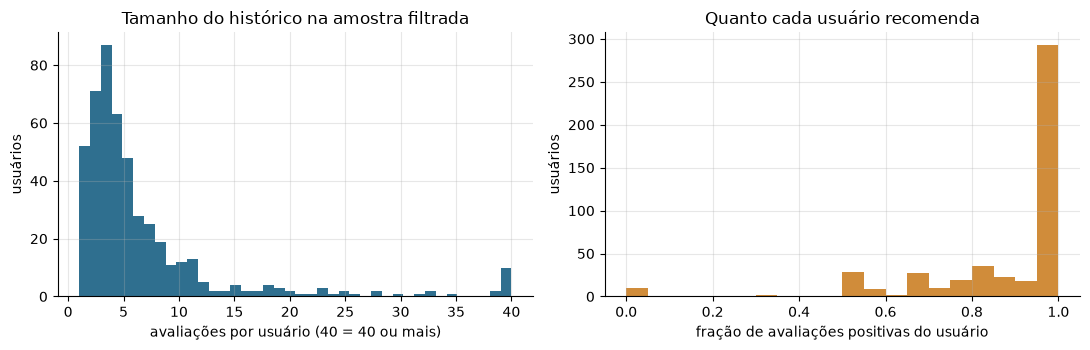

Usuários que só avaliaram positivamente: 60.0%; sem nenhuma positiva: 2.1%


In [13]:
perdas = amostra.assign(no_catalogo=amostra["app_id"].isin(catalogo_aval))
motivo = perdas.loc[~perdas["no_catalogo"], "app_id"].map(
    lambda i: "sem descrição" if i not in set(bruto.loc[~descricao_vazia, "app_id"]) else "extra (DLC, trilha etc.)")
print("Por que interações da amostra saíram:")
print(motivo.value_counts().to_string())

n_hist = filtrada.groupby("user_id")["app_id"].count()
taxa = filtrada.groupby("user_id")["is_recommended"].mean()
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
a.hist(n_hist.clip(upper=40), bins=40, color=COR)
a.set_xlabel("avaliações por usuário (40 = 40 ou mais)")
a.set_ylabel("usuários")
a.set_title("Tamanho do histórico na amostra filtrada")
b.hist(taxa, bins=20, color=COR2)
b.set_xlabel("fração de avaliações positivas do usuário")
b.set_ylabel("usuários")
b.set_title("Quanto cada usuário recomenda")
salvar(fig, "06_amostra_usuarios")
plt.show()
print(f"Usuários que só avaliaram positivamente: {(taxa == 1).mean():.1%}; "
      f"sem nenhuma positiva: {(taxa == 0).mean():.1%}")

**Leitura.**

- **O filtro de descrição derruba 40% das interações da amostra** (2.509 de 6.214); o filtro de extras, só 17. Depois disso, a mediana de jogos por usuário cai de 8 para 4, e só 210 dos 483 usuários restantes continuam com 5 ou mais (o mínimo para ir ao teste). É o mesmo problema da seção 1.2 visto pelo lado do usuário: os jogos que ele mais joga às vezes nem estão no catálogo.
- No fim, **185 usuários** têm ao menos um jogo relevante no teste, com média de 2,6 jogos relevantes cada. Isso explica os valores absolutos baixos das métricas: acertar 2 ou 3 jogos específicos entre mais de 8 mil candidatos é difícil.
- **60% dos usuários nunca avaliaram negativamente**, então para a maioria o perfil é só a soma dos jogos de que gostou.
- O teste tem um pouco menos de positivas (80,6%) que o treino (86,3%). Diferença pequena, mas indica que as avaliações mais recentes são um pouco mais críticas.

## 8. Resumo: achados e decisões

| Achado | Decisão no sistema |
| --- | --- |
| 20% dos jogos sem descrição; preço e data completos | Catálogo exige descrição; mediana imputada por segurança nos numéricos |
| ~1.200 jogos sem descrição e sem tags concentram ~62% das avaliações (CS:GO, Dota 2, GTA V...) | **Limitação principal.** Próximo passo: completar metadados por fonte externa (API da Steam) |
| Descrições curtas (≈ 37 palavras) e ≈ 17 tags por jogo | Tag inteira com peso 4 no TF-IDF; IDF reduz as tags genéricas |
| Palavras do domínio em toda descrição (*game*, *play*) | Incluídas nas stopwords |
| Itens que não são jogos (prólogos, trilhas, DLCs) | Filtro por título; perde só 17 interações da amostra |
| Preço muito assimétrico (skew 1,53) | `log(1 + preço)` antes do z-score |
| Atributos em escalas diferentes | z-score limitado a ±3 (variante preço/ano) |
| 86% das avaliações são positivas | Relevante = `is_recommended = True` |
| Mediana de 1 avaliação por usuário | Amostra só com usuários com ≥ 5 jogos |
| Popularidade em cauda longa (1% dos jogos = 70% das avaliações) | Baseline de populares, cobertura e diversidade como métricas extras |
| Matriz 0,008% preenchida | Reforça o uso de FBC em vez de colaborativa |